# EN3150 Assignment 03: Train & evaluate everything (Kaggle / Colab)

Runs every experiment the assignment needs **on one GPU**, so the *time per epoch* column is comparable across models.

| Assignment part | Cells |
|---|---|
| 1. Data prep (64×64, 70/15/15) | Step 2 |
| 3. Optimizer comparison (Adam vs SGD vs SGD+Momentum) | Step 4 |
| 4. Model A & B, 20 epochs, loss curves, test metrics, A-vs-B table | Steps 3, 6, 7 |
| 5. Fine-tune MobileNetV2 + EfficientNet-B0, params + size (MB) | Step 5 |
| 6. Model B vs SOTA comparison | Step 7 |

**Before running:**
- **Kaggle:** right sidebar → *Accelerator* = **GPU T4 x2** (or P100), *Internet* = **On**. Then use **Save Version → Save & Run All (Commit)** so it runs in the background, and download from the *Output* tab.
- **Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Keep the tab open; Step 8 saves results to Google Drive.

## Step 0: Settings

In [1]:
REPO_URL = "https://github.com/rash200319/CNN-for-image-classification.git"
REPO_BRANCH = "main"
# Private repo? use: "https://<YOUR_GITHUB_TOKEN>@github.com/rash200319/CNN-for-image-classification.git"

EPOCHS_CUSTOM = 20   # assignment: at least 20 epochs for Model A and Model B
EPOCHS_SOTA   = 5    # fine-tuning epochs for the pretrained models
RUN_MODEL_A_OPTIMIZER_SWEEP = False  # True = also compare SGD / SGD+Momentum for Model A (optional, +~2 runs)

## Step 1: Detect platform, check GPU, clone the repo

In [2]:
import os, sys, subprocess, pathlib

ON_KAGGLE = os.path.exists("/kaggle")
ON_COLAB  = "google.colab" in sys.modules
WORK_DIR  = pathlib.Path("/kaggle/working") if ON_KAGGLE else pathlib.Path("/content")
REPO_DIR  = WORK_DIR / "CNN-for-image-classification"
print("Platform:", "Kaggle" if ON_KAGGLE else "Colab" if ON_COLAB else "Other/local")

import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU, enable it in the notebook settings, otherwise training is very slow.")

import socket, shutil
def has_internet(host="github.com"):
    try:
        socket.gethostbyname(host); return True
    except OSError:
        return False

HAS_INTERNET = has_internet()
print("Internet:", HAS_INTERNET)

if HAS_INTERNET:
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
elif not REPO_DIR.exists():
    # Offline fallback: repo uploaded as a Kaggle dataset (any folder under /kaggle/input containing src/train.py)
    found = next((p.parent.parent for p in pathlib.Path("/kaggle/input").rglob("src/train.py")), None)
    if found is None:
        raise RuntimeError(
            "No internet. On Kaggle: right sidebar -> Session options -> Internet = ON "
            "(needs a phone-verified account, Settings -> Phone verification), then Restart & Run All.\n"
            "Or upload the repo folder as a Kaggle dataset and attach it with '+ Add Input'.")
    shutil.copytree(found, REPO_DIR, ignore=shutil.ignore_patterns(".git", "__pycache__"))
    print("Copied repo from", found)

os.chdir(REPO_DIR)
print("Working in:", os.getcwd())

Platform: Kaggle
torch 2.11.0+cu128 | CUDA available: True
GPU: Tesla T4
Internet: True


Cloning into '/kaggle/working/CNN-for-image-classification'...


Working in: /kaggle/working/CNN-for-image-classification


In [3]:
# torch / torchvision / sklearn / pandas / matplotlib are preinstalled on Kaggle & Colab
!pip install -q tqdm

## Step 2: Get the EuroSAT RGB dataset
The code expects the images at `archive/EuroSAT/<ClassName>/*.jpg`. This cell:
1. looks for an already-attached copy (a Kaggle dataset under `/kaggle/input`, or a folder in your Google Drive), otherwise
2. downloads EuroSAT RGB (~90 MB) with `torchvision`,

then links it to `archive/EuroSAT`.

In [4]:
from pathlib import Path

def find_eurosat(root):
    root = Path(root)
    if not root.exists():
        return None
    for p in root.rglob("AnnualCrop"):
        if p.is_dir() and (p.parent / "SeaLake").is_dir() and any(p.glob("*.jpg")):
            return p.parent
    return None

search_roots = ["/kaggle/input"]
if ON_COLAB:
    # Optional: put your EuroSAT_RGB folder in Google Drive and it will be used instead of downloading
    from google.colab import drive
    drive.mount("/content/drive")
    search_roots.append("/content/drive/MyDrive")

data_root = None
for r in search_roots:
    data_root = find_eurosat(r)
    if data_root:
        break

if data_root is None:
    print("No local copy found, downloading EuroSAT RGB with torchvision ...")
    from torchvision.datasets import EuroSAT
    EuroSAT(root="/tmp/eurosat_dl", download=True)
    data_root = find_eurosat("/tmp/eurosat_dl")

assert data_root is not None, "EuroSAT not found / download failed"
print("Dataset folder:", data_root)

link = REPO_DIR / "archive" / "EuroSAT"
link.parent.mkdir(exist_ok=True)
if link.is_symlink() or link.exists():
    link.unlink()
link.symlink_to(data_root, target_is_directory=True)

classes = sorted(d.name for d in link.iterdir() if d.is_dir())
n_imgs = sum(len(list((link / c).glob("*.jpg"))) for c in classes)
print(f"{len(classes)} classes, {n_imgs} images:", classes)
assert len(classes) == 10 and n_imgs == 27000

No local copy found, downloading EuroSAT RGB with torchvision ...


100%|██████████| 94.3M/94.3M [00:01<00:00, 85.0MB/s]


Dataset folder: /tmp/eurosat_dl/eurosat/2750
10 classes, 27000 images: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [5]:
# Sanity check: split sizes + parameter counts (Model B must be <= 100k)
from src.data.dataset import get_dataloaders
from src.models.model_a import ModelA
from src.models.model_b import ModelB
from src.utils import count_parameters

tr, va, te, cls = get_dataloaders()
print(f"train={len(tr.dataset)}  val={len(va.dataset)}  test={len(te.dataset)}")
print(f"Model A params: {count_parameters(ModelA(10)):,}")
print(f"Model B params: {count_parameters(ModelB(10)):,}  (limit 100,000)")

train=18900  val=4049  test=4051
Model A params: 549,290
Model B params: 13,288  (limit 100,000)


## Step 3: Train Model A and Model B with Adam (Part 4)

In [6]:
!python -m src.train --model a --optimizer adam --lr 1e-3 --epochs {EPOCHS_CUSTOM} --run-name final_a_adam

final_a_adam: 549,290 trainable params on cuda
final_a_adam: 100%|█████████████████████████████| 20/20 [02:52<00:00,  8.60s/it]
Done. Best val_acc=0.8940. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_a_adam


In [7]:
!python -m src.train --model b --optimizer adam --lr 1e-3 --epochs {EPOCHS_CUSTOM} --run-name modelb_adam

modelb_adam: 13,288 trainable params on cuda
modelb_adam: 100%|██████████████████████████████| 20/20 [02:53<00:00,  8.68s/it]
Done. Best val_acc=0.9108. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_adam


## Step 4: Optimizer comparison on Model B: plain SGD vs SGD + Momentum (Part 3)

In [8]:
!python -m src.train --model b --optimizer sgd          --lr 1e-2                --epochs {EPOCHS_CUSTOM} --run-name modelb_sgd
!python -m src.train --model b --optimizer sgd_momentum --lr 1e-2 --momentum 0.9 --epochs {EPOCHS_CUSTOM} --run-name modelb_sgd_momentum

modelb_sgd: 13,288 trainable params on cuda
modelb_sgd: 100%|███████████████████████████████| 20/20 [02:49<00:00,  8.49s/it]
Done. Best val_acc=0.7982. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_sgd
modelb_sgd_momentum: 13,288 trainable params on cuda
modelb_sgd_momentum: 100%|██████████████████████| 20/20 [02:51<00:00,  8.56s/it]
Done. Best val_acc=0.8908. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_sgd_momentum


In [9]:
# Optional: same comparison for Model A
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    !python -m src.train --model a --optimizer sgd          --lr 1e-2                --epochs {EPOCHS_CUSTOM} --run-name modela_sgd
    !python -m src.train --model a --optimizer sgd_momentum --lr 1e-2 --momentum 0.9 --epochs {EPOCHS_CUSTOM} --run-name modela_sgd_momentum

## Step 5: Fine-tune the two lightweight pretrained models (Part 5)

Both SOTA compliance runs use the assignment maximum of 64x64. The historical 128x128 MobileNetV2 result is not regenerated here and must be treated only as an optional resolution study.


In [10]:
!python -m src.train --model mobilenet_v2    --optimizer adam --lr 1e-4 --img-size 64 --epochs {EPOCHS_SOTA} --run-name final_mobilenet_v2
!python -m src.train --model efficientnet_b0 --optimizer adam --lr 1e-4 --img-size 64  --epochs {EPOCHS_SOTA} --run-name final_efficientnet_b0

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|███████████████████████████████████████| 13.6M/13.6M [00:00<00:00, 203MB/s]
final_mobilenet_v2: 2,236,682 trainable params on cuda
final_mobilenet_v2: 100%|█████████████████████████| 5/5 [01:02<00:00, 12.50s/it]
Done. Best val_acc=0.9738. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_mobilenet_v2
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|███████████████████████████████████████| 20.5M/20.5M [00:00<00:00, 253MB/s]
final_efficientnet_b0: 4,020,358 trainable params on cuda
final_efficientnet_b0: 100%|██████████████████████| 5/5 [01:23<00:00, 16.74s/it]
Done. Best val_acc=0.9699. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_efficientnet_b0


## Step 6: Evaluate on the test set and plot loss curves

In [11]:
RUNS = {  # run_name: (model flag, img size)
    "final_a_adam":          ("a", 64),
    "modelb_adam":           ("b", 64),
    "modelb_sgd":            ("b", 64),
    "modelb_sgd_momentum":   ("b", 64),
    "final_mobilenet_v2":    ("mobilenet_v2", 64),
    "final_efficientnet_b0": ("efficientnet_b0", 64),
}
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    RUNS.update({"modela_sgd": ("a", 64), "modela_sgd_momentum": ("a", 64)})

for run, (m, size) in RUNS.items():
    print(f"\n===== {run} =====")
    !python -m src.evaluate --model {m} --checkpoint outputs/{run}/best_model.pt --img-size {size}
    !python -m src.plot_history --run-dir outputs/{run}


===== final_a_adam =====
test_accuracy=0.9003 precision_macro=0.9020 recall_macro=0.8946
params=549,290 checkpoint_size_kb=2150.1
Confusion matrix saved to outputs/final_a_adam/confusion_matrix.png
Full metrics saved to outputs/final_a_adam/metrics.json
Saved plot to outputs/final_a_adam/loss_curve.png

===== modelb_adam =====
test_accuracy=0.9101 precision_macro=0.9087 recall_macro=0.9064
params=13,288 checkpoint_size_kb=63.9
Confusion matrix saved to outputs/modelb_adam/confusion_matrix.png
Full metrics saved to outputs/modelb_adam/metrics.json
Saved plot to outputs/modelb_adam/loss_curve.png

===== modelb_sgd =====
test_accuracy=0.7988 precision_macro=0.7967 recall_macro=0.7879
params=13,288 checkpoint_size_kb=63.9
Confusion matrix saved to outputs/modelb_sgd/confusion_matrix.png
Full metrics saved to outputs/modelb_sgd/metrics.json
Saved plot to outputs/modelb_sgd/loss_curve.png

===== modelb_sgd_momentum =====
test_accuracy=0.8990 precision_macro=0.8963 recall_macro=0.8968
params

In [12]:
# Overlay plots: optimizer comparison (Part 3) and Model A vs B (Part 4)
!python -m src.plot_history --run-dir outputs/modelb_adam --run-dir outputs/modelb_sgd --run-dir outputs/modelb_sgd_momentum --out outputs/modelb_optimizer_comparison.png
!python -m src.plot_history --run-dir outputs/final_a_adam --run-dir outputs/modelb_adam --out outputs/modelA_vs_modelB_loss.png
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    !python -m src.plot_history --run-dir outputs/final_a_adam --run-dir outputs/modela_sgd --run-dir outputs/modela_sgd_momentum --out outputs/modela_optimizer_comparison.png

Saved plot to outputs/modelb_optimizer_comparison.png
Saved plot to outputs/modelA_vs_modelB_loss.png


## Step 7: Results tables for the report (Parts 3, 4, 5, 6)

In [13]:
import json, pandas as pd
from IPython.display import display, Image, Markdown

rows = []
for run in RUNS:
    d = Path("outputs") / run
    m = json.load(open(d / "metrics.json"))
    h = pd.read_csv(d / "history.csv")
    rows.append({
        "run": run,
        "params": m["trainable_params"],
        "size_KB": round(m["checkpoint_size_kb"], 1),
        "size_MB": round(m["checkpoint_size_kb"] / 1024, 3),
        "epochs": len(h),
        "median_s_per_epoch": round(h["epoch_time_sec"].median(), 2),
        "best_val_acc_%": round(100 * h["val_acc"].max(), 2),
        "test_acc_%": round(100 * m["test_accuracy"], 2),
        "precision_macro": round(m["precision_macro"], 4),
        "recall_macro": round(m["recall_macro"], 4),
        "f1_macro": round(m["f1_macro"], 4),
    })
df = pd.DataFrame(rows).set_index("run")
df.to_csv("outputs/all_results.csv")

display(Markdown("### Part 3: Optimizer comparison (Model B)"))
display(df.loc[["modelb_adam", "modelb_sgd", "modelb_sgd_momentum"]])
display(Markdown("### Part 4: Model A vs Model B"))
display(df.loc[["final_a_adam", "modelb_adam"], ["params", "size_KB", "median_s_per_epoch", "test_acc_%"]])
display(Markdown("### Parts 5 & 6: Model B vs lightweight SOTA"))
display(df.loc[["modelb_adam", "final_mobilenet_v2", "final_efficientnet_b0"],
               ["params", "size_MB", "median_s_per_epoch", "test_acc_%", "precision_macro", "recall_macro"]])

print("GPU used:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print(df.to_markdown())

### Part 3: Optimizer comparison (Model B)

,params,size_KB,size_MB,epochs,median_s_per_epoch,best_val_acc_%,test_acc_%,precision_macro,recall_macro,f1_macro
run,,,,,,,,,,
modelb_adam,13288,63.9,0.062,20,8.66,91.08,91.01,0.9087,0.9064,0.9067
modelb_sgd,13288,63.9,0.062,20,8.42,79.82,79.88,0.7967,0.7879,0.7833
modelb_sgd_momentum,13288,63.9,0.062,20,8.56,89.08,89.90,0.8963,0.8968,0.8957


### Part 4: Model A vs Model B

,params,size_KB,median_s_per_epoch,test_acc_%
run,,,,
final_a_adam,549290,2150.1,8.53,90.03
modelb_adam,13288,63.9,8.66,91.01


### Parts 5 & 6: Model B vs lightweight SOTA

,params,size_MB,median_s_per_epoch,test_acc_%,precision_macro,recall_macro
run,,,,,,
modelb_adam,13288,0.062,8.66,91.01,0.9087,0.9064
final_mobilenet_v2,2236682,8.766,12.45,97.58,0.9752,0.9743
final_efficientnet_b0,4020358,15.622,16.39,97.36,0.9732,0.9721


GPU used: Tesla T4
| run                   |           params |   size_KB |   size_MB |   epochs |   median_s_per_epoch |   best_val_acc_% |   test_acc_% |   precision_macro |   recall_macro |   f1_macro |
|:----------------------|-----------------:|----------:|----------:|---------:|---------------------:|-----------------:|-------------:|------------------:|---------------:|-----------:|
| final_a_adam          | 549290           |    2150.1 |     2.1   |       20 |                 8.53 |            89.4  |        90.03 |            0.902  |         0.8946 |     0.8964 |
| modelb_adam           |  13288           |      63.9 |     0.062 |       20 |                 8.66 |            91.08 |        91.01 |            0.9087 |         0.9064 |     0.9067 |
| modelb_sgd            |  13288           |      63.9 |     0.062 |       20 |                 8.42 |            79.82 |        79.88 |            0.7967 |         0.7879 |     0.7833 |
| modelb_sgd_momentum   |  13288           |  

In [14]:
# Per-class precision / recall (for the report's confusion-matrix discussion)
for run in ["final_a_adam", "modelb_adam", "final_mobilenet_v2", "final_efficientnet_b0"]:
    pc = json.load(open(f"outputs/{run}/metrics.json"))["per_class"]
    display(Markdown(f"**{run}**"))
    display(pd.DataFrame(pc).T.round(4))

**final_a_adam**

,precision,recall,f1,support
AnnualCrop,0.8848,0.9044,0.8945,450.0
Forest,0.9231,0.9867,0.9538,450.0
HerbaceousVegetation,0.8571,0.8780,0.8675,451.0
Highway,0.9402,0.7547,0.8373,375.0
Industrial,0.9267,0.9440,0.9353,375.0
Pasture,0.9502,0.8267,0.8841,300.0
PermanentCrop,0.8306,0.8240,0.8273,375.0
Residential,0.9194,0.9889,0.9529,450.0
River,0.8133,0.8827,0.8465,375.0
SeaLake,0.9751,0.9556,0.9652,450.0


**modelb_adam**

,precision,recall,f1,support
AnnualCrop,0.8796,0.9089,0.8940,450.0
Forest,0.9713,0.9778,0.9745,450.0
HerbaceousVegetation,0.8580,0.9246,0.8901,451.0
Highway,0.9250,0.7893,0.8518,375.0
Industrial,0.9082,0.9760,0.9409,375.0
Pasture,0.9033,0.9033,0.9033,300.0
PermanentCrop,0.8228,0.8293,0.8260,375.0
Residential,0.9752,0.9622,0.9687,450.0
River,0.8533,0.8373,0.8452,375.0
SeaLake,0.9908,0.9556,0.9729,450.0


**final_mobilenet_v2**

,precision,recall,f1,support
AnnualCrop,0.9524,0.9778,0.9649,450.0
Forest,0.9912,0.9956,0.9933,450.0
HerbaceousVegetation,0.9649,0.9756,0.9702,451.0
Highway,0.9753,0.9467,0.9608,375.0
Industrial,0.9946,0.9813,0.9879,375.0
Pasture,0.9567,0.9567,0.9567,300.0
PermanentCrop,0.9592,0.9413,0.9502,375.0
Residential,0.9890,0.9978,0.9934,450.0
River,0.9735,0.9813,0.9774,375.0
SeaLake,0.9955,0.9889,0.9922,450.0


**final_efficientnet_b0**

,precision,recall,f1,support
AnnualCrop,0.9581,0.9667,0.9624,450.0
Forest,0.9890,0.9956,0.9922,450.0
HerbaceousVegetation,0.9465,0.9800,0.9630,451.0
Highway,0.9653,0.9653,0.9653,375.0
Industrial,0.9867,0.9867,0.9867,375.0
Pasture,0.9596,0.9500,0.9548,300.0
PermanentCrop,0.9617,0.9387,0.9501,375.0
Residential,0.9889,0.9889,0.9889,450.0
River,0.9783,0.9627,0.9704,375.0
SeaLake,0.9978,0.9867,0.9922,450.0


### final_a_adam

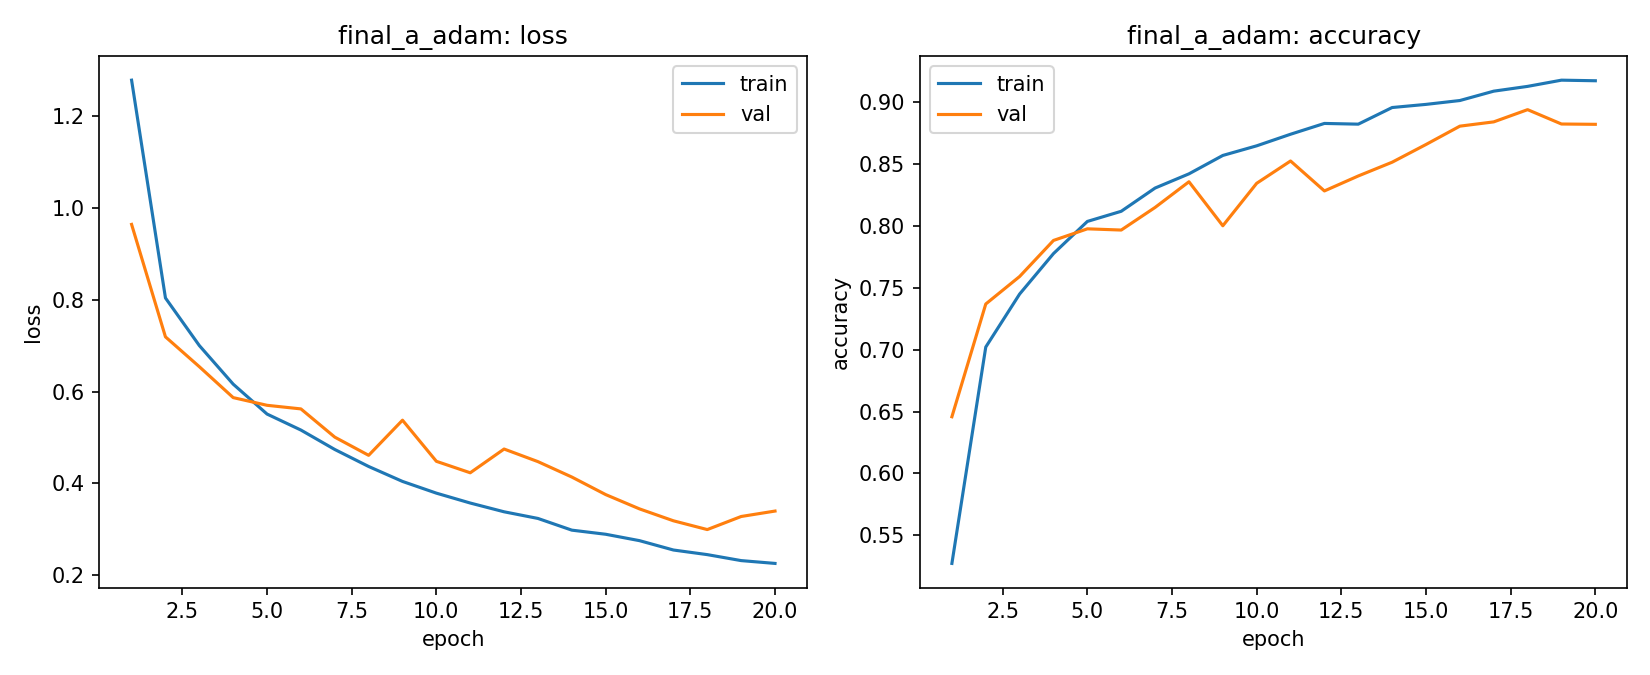

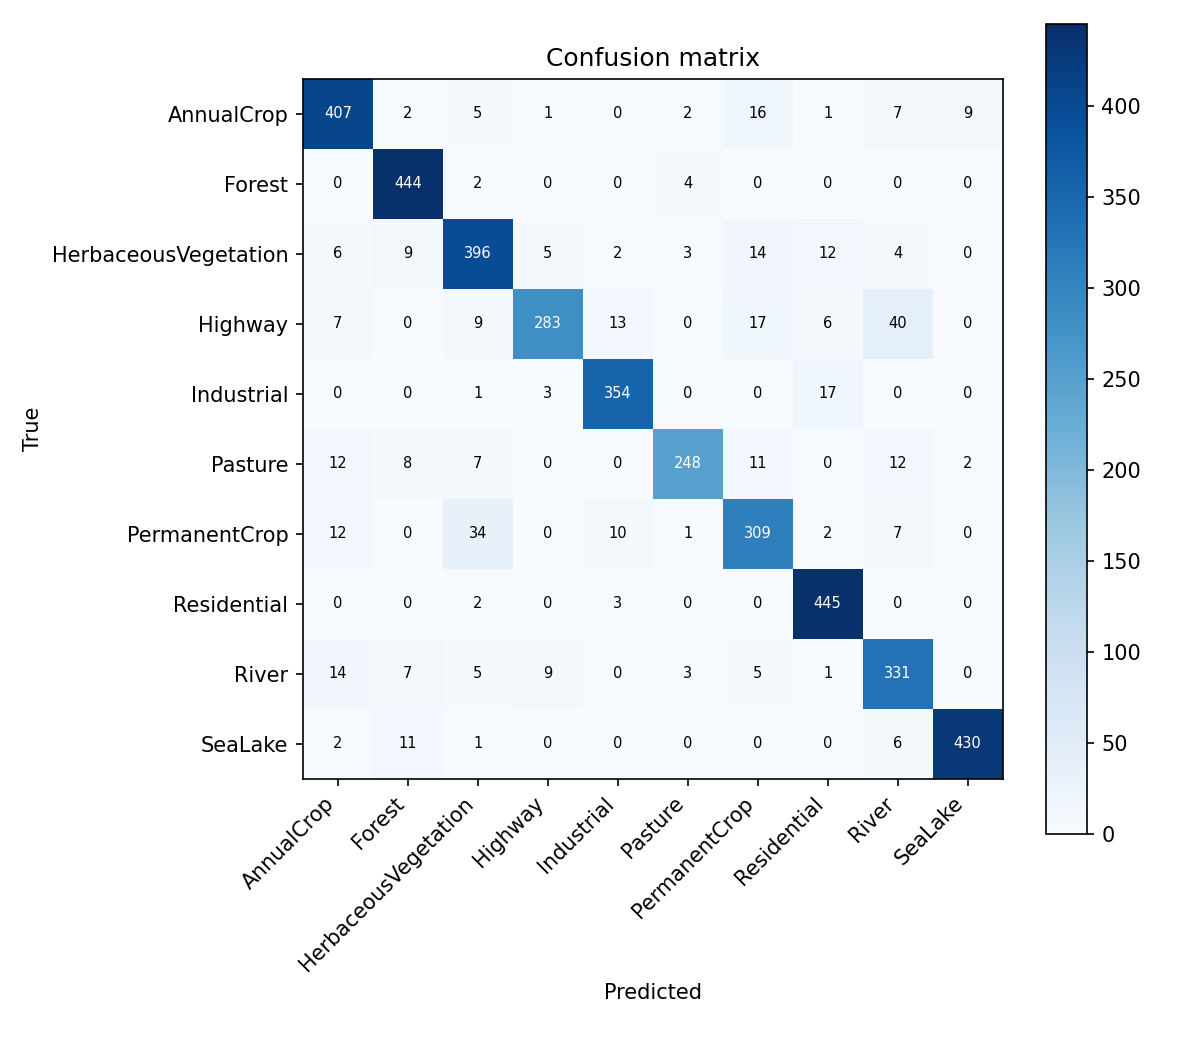

### modelb_adam

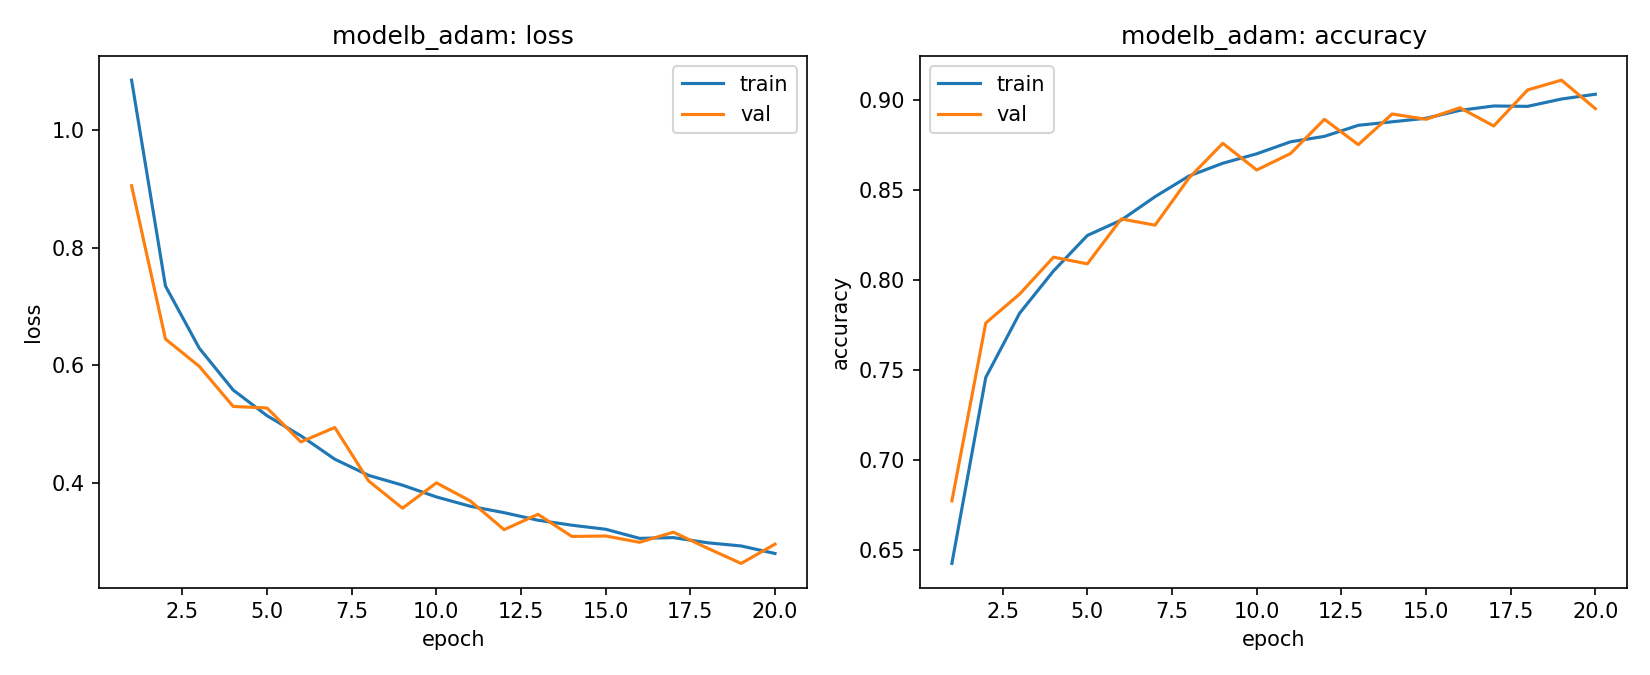

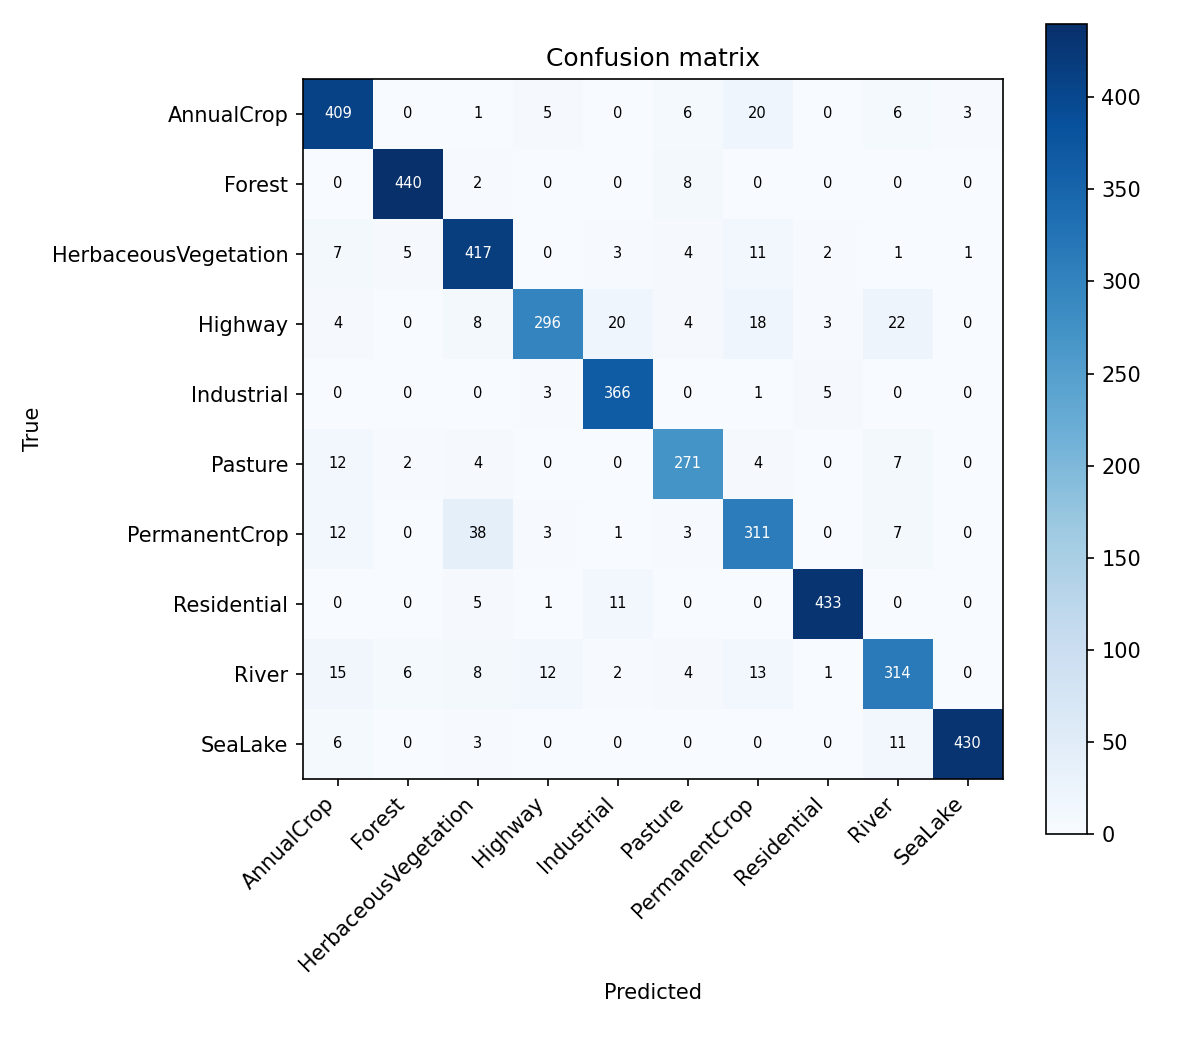

### modelb_sgd

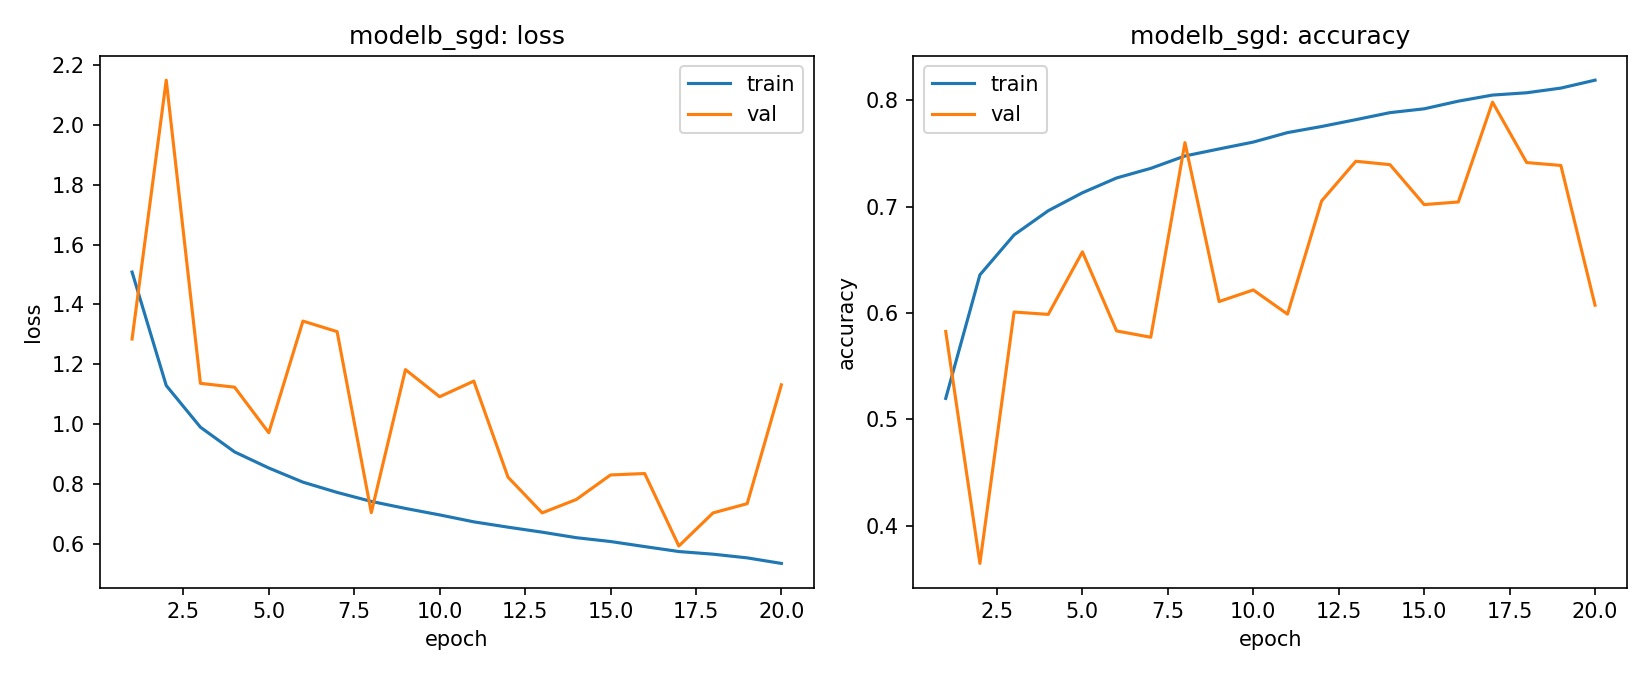

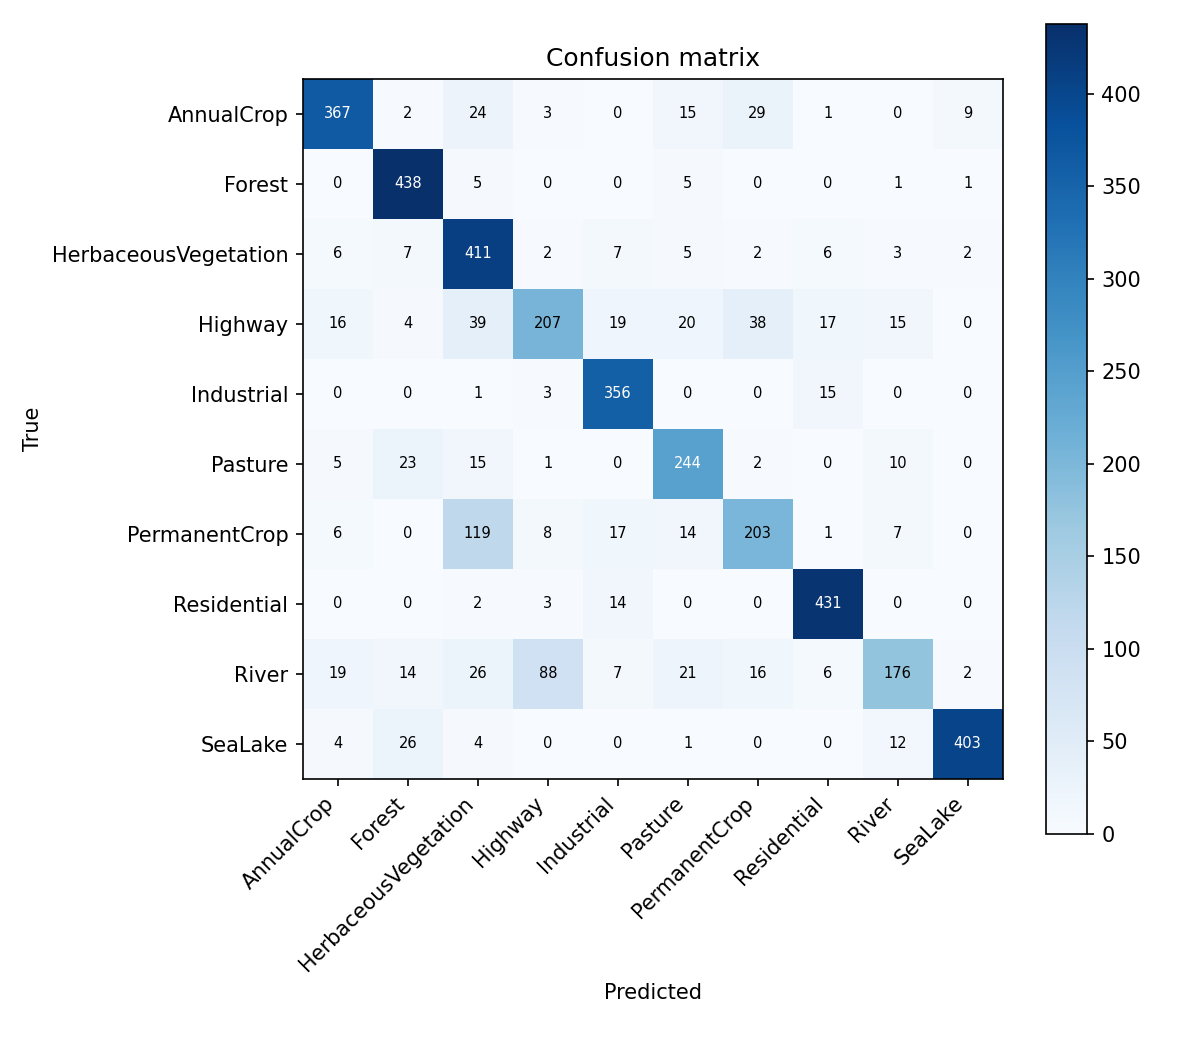

### modelb_sgd_momentum

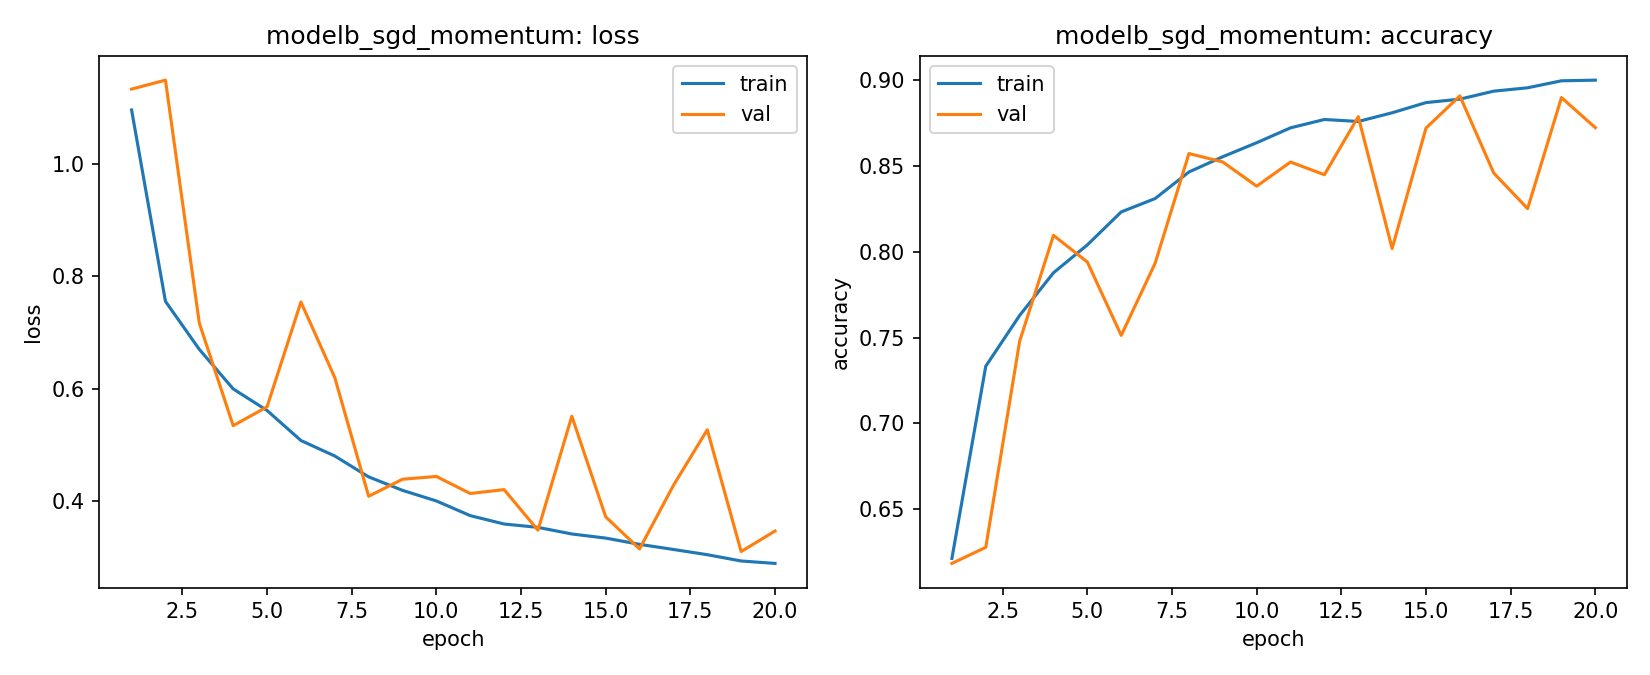

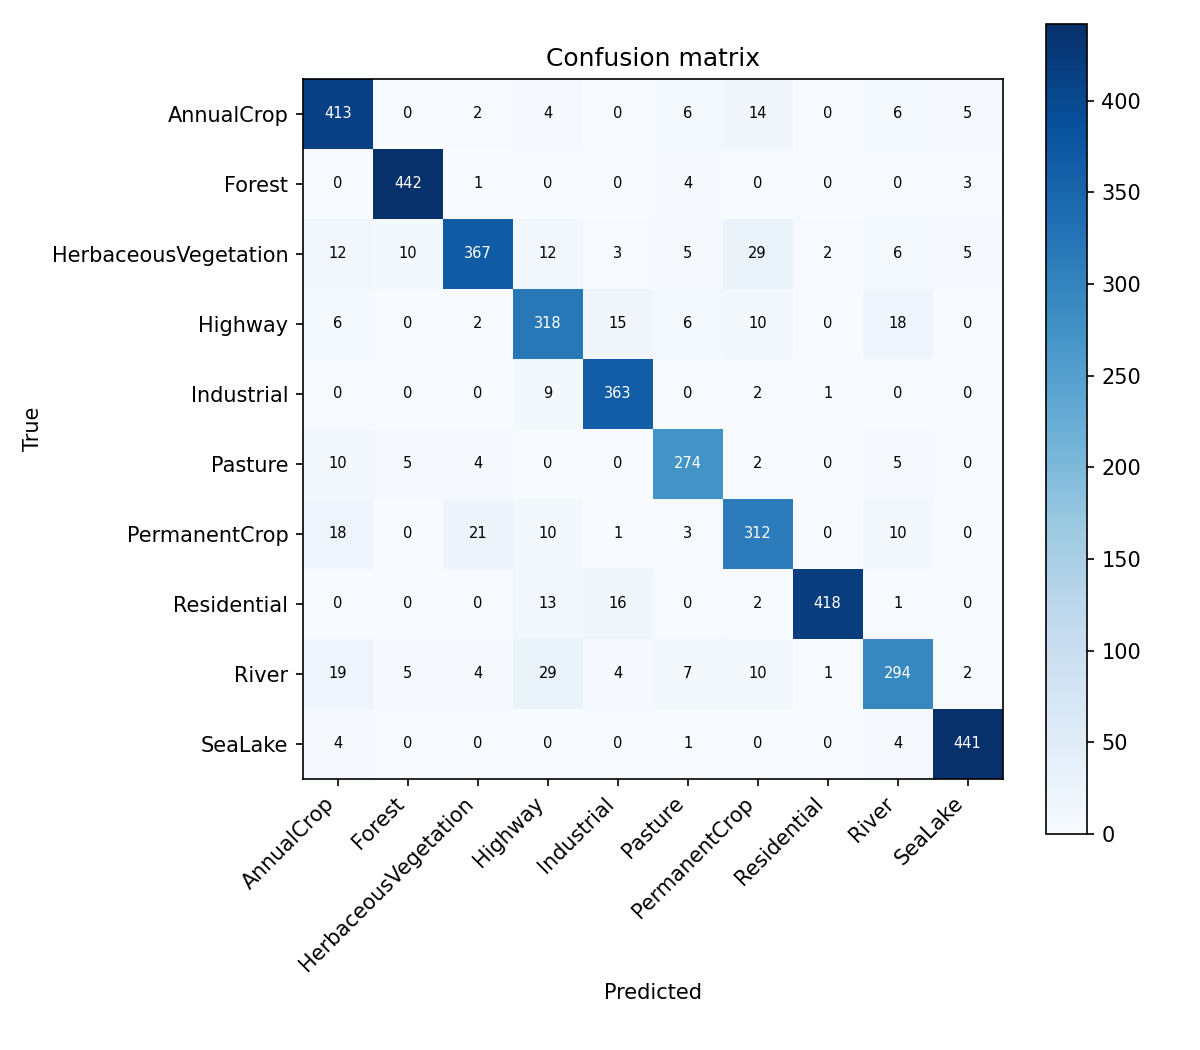

### final_mobilenet_v2

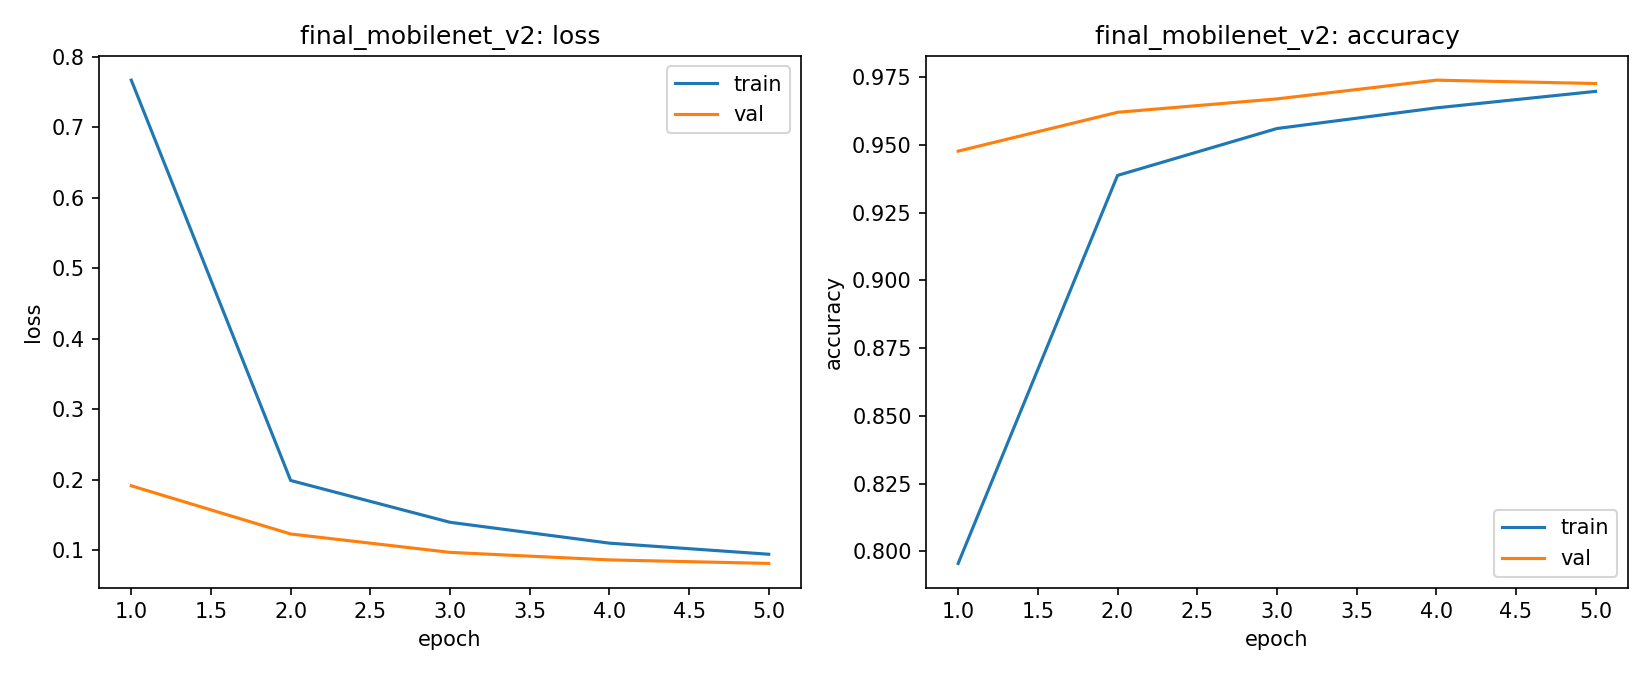

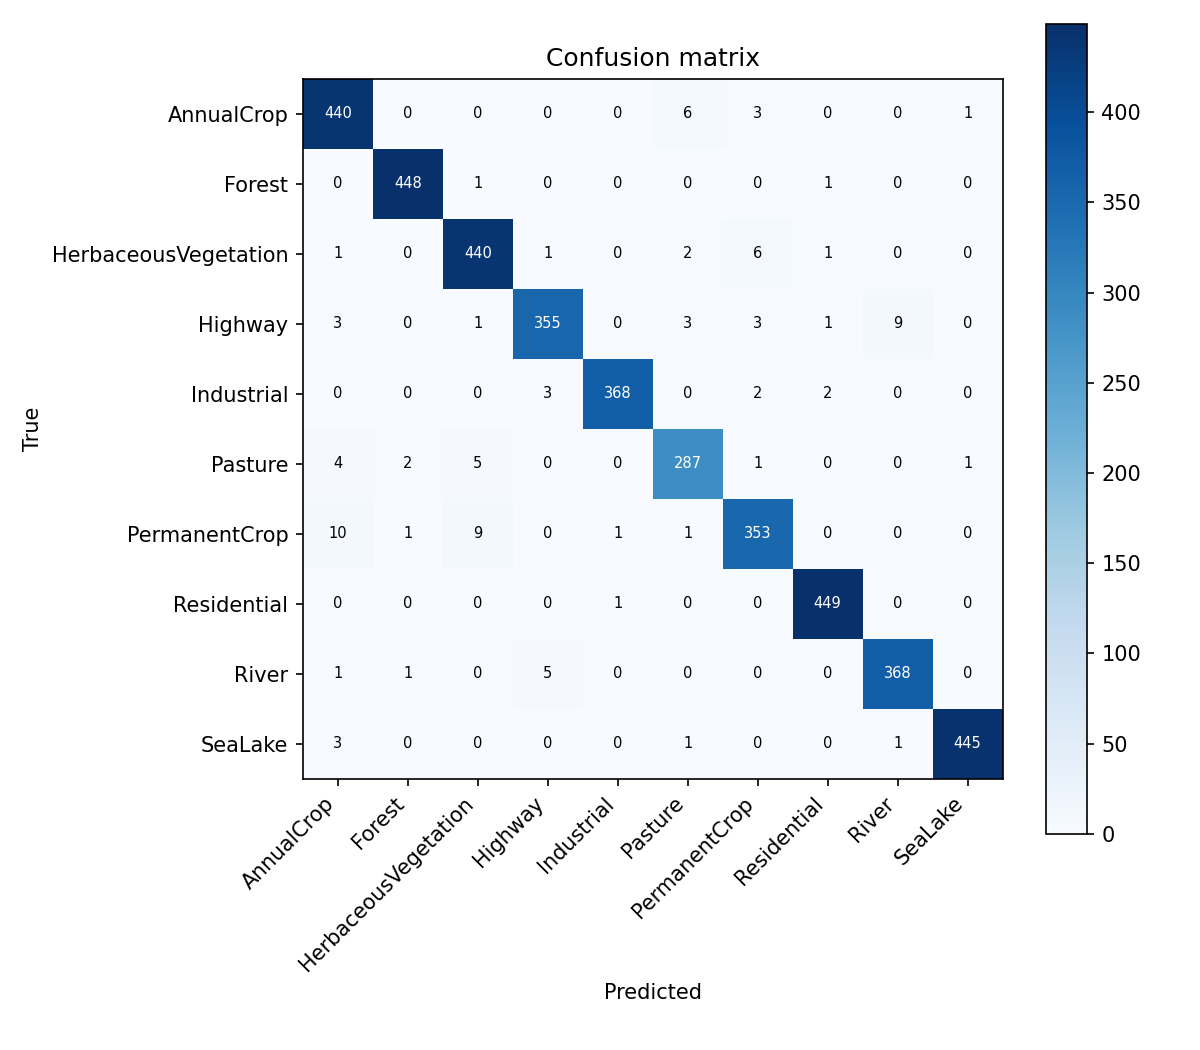

### final_efficientnet_b0

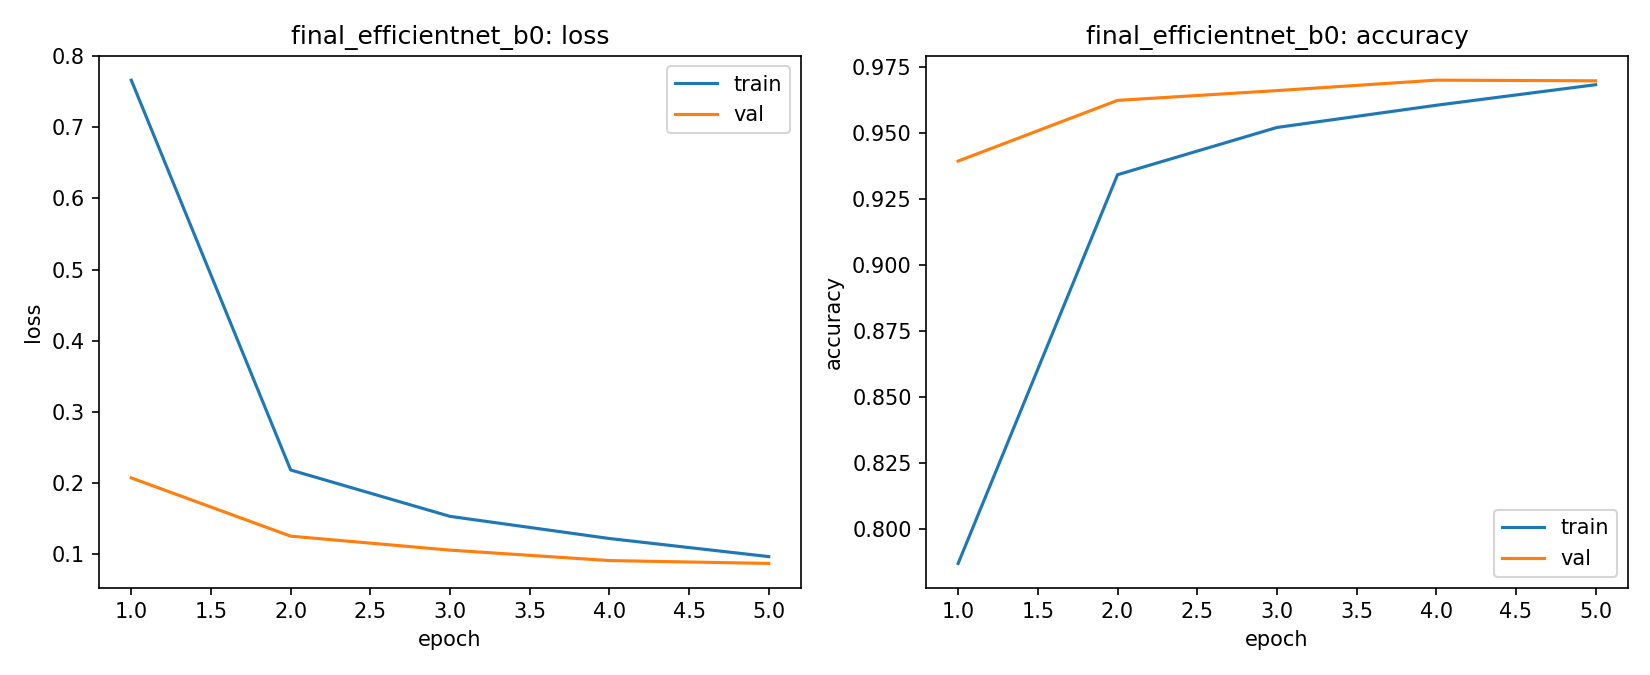

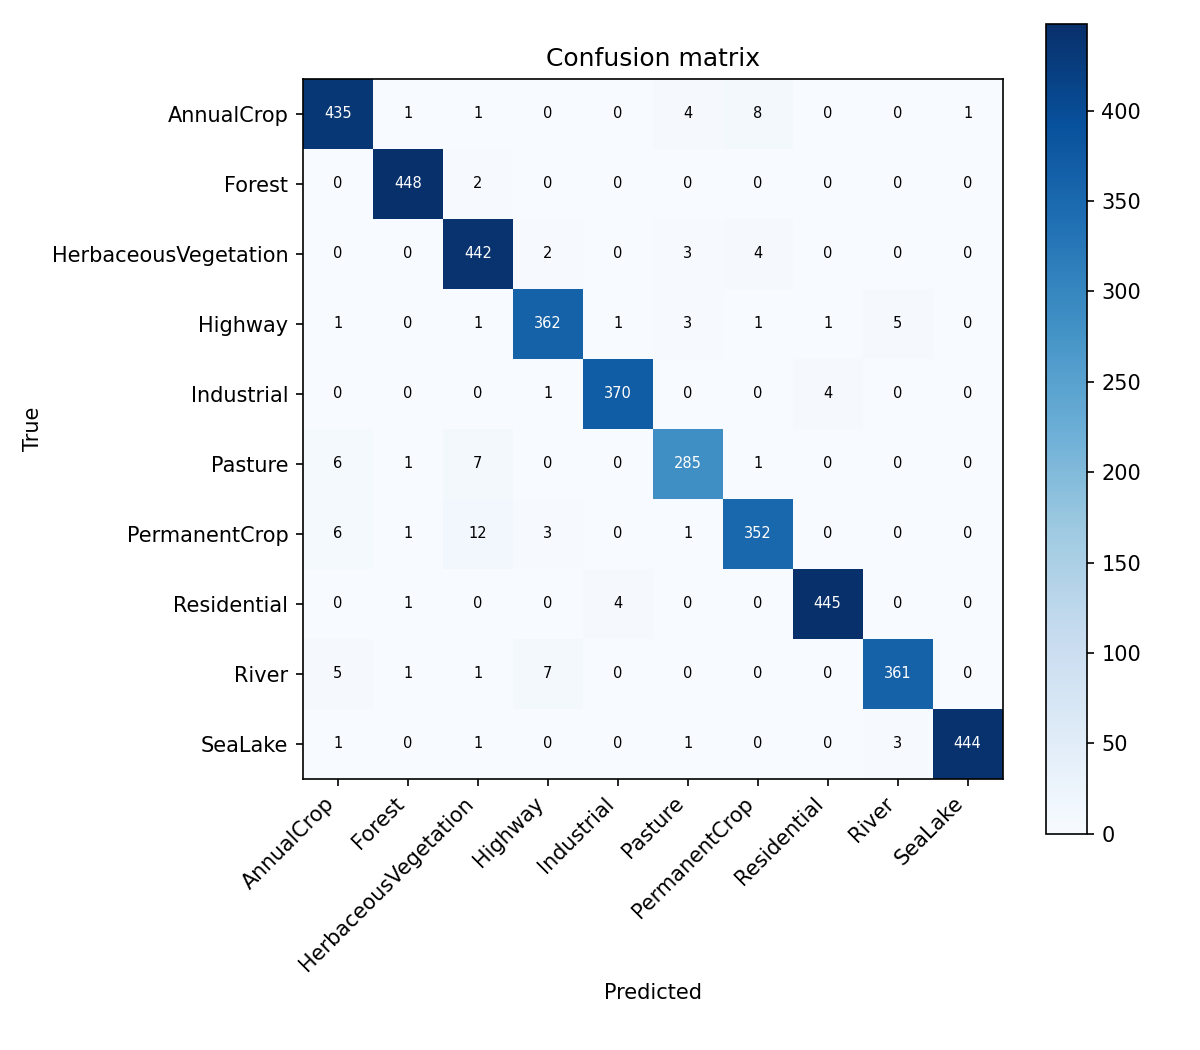

### modelb_optimizer_comparison.png

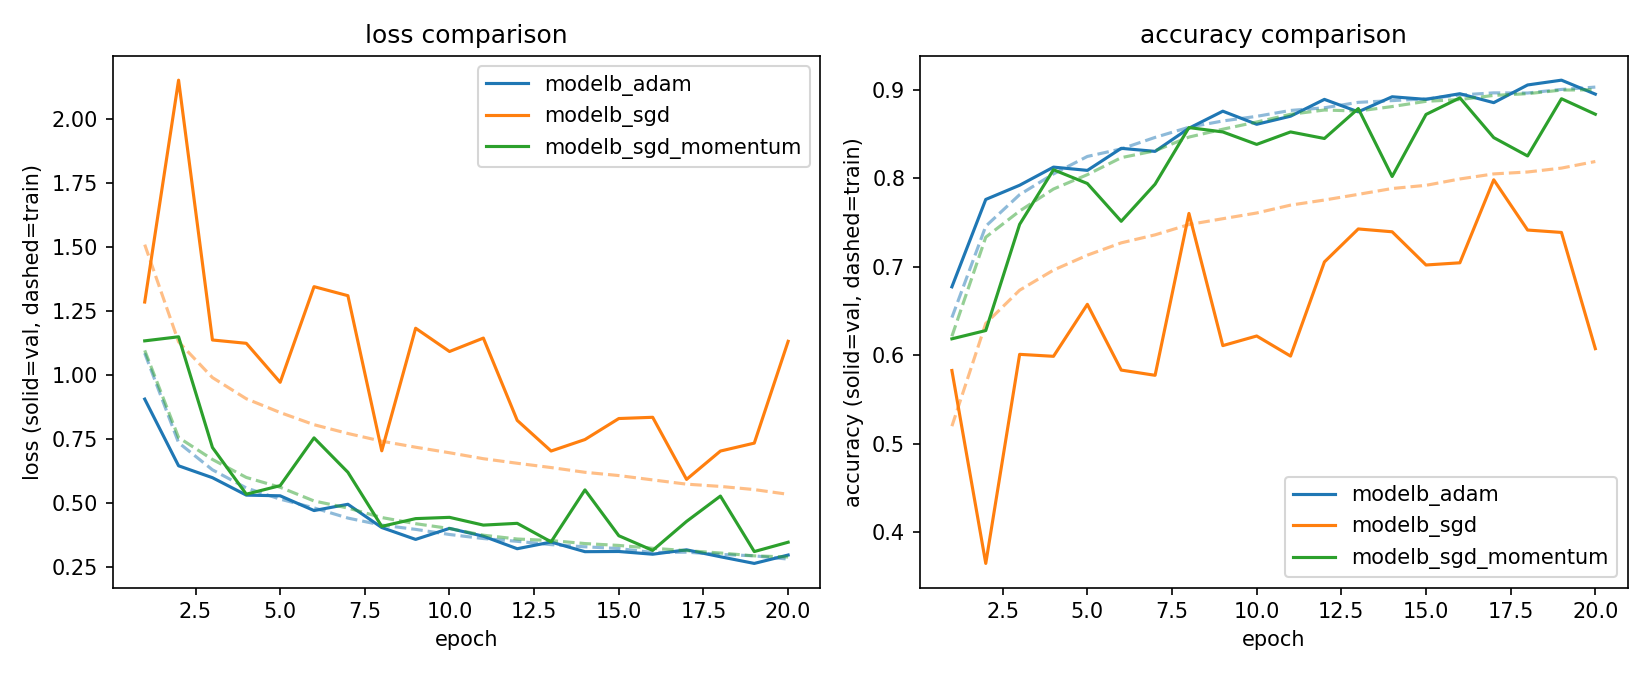

### modelA_vs_modelB_loss.png

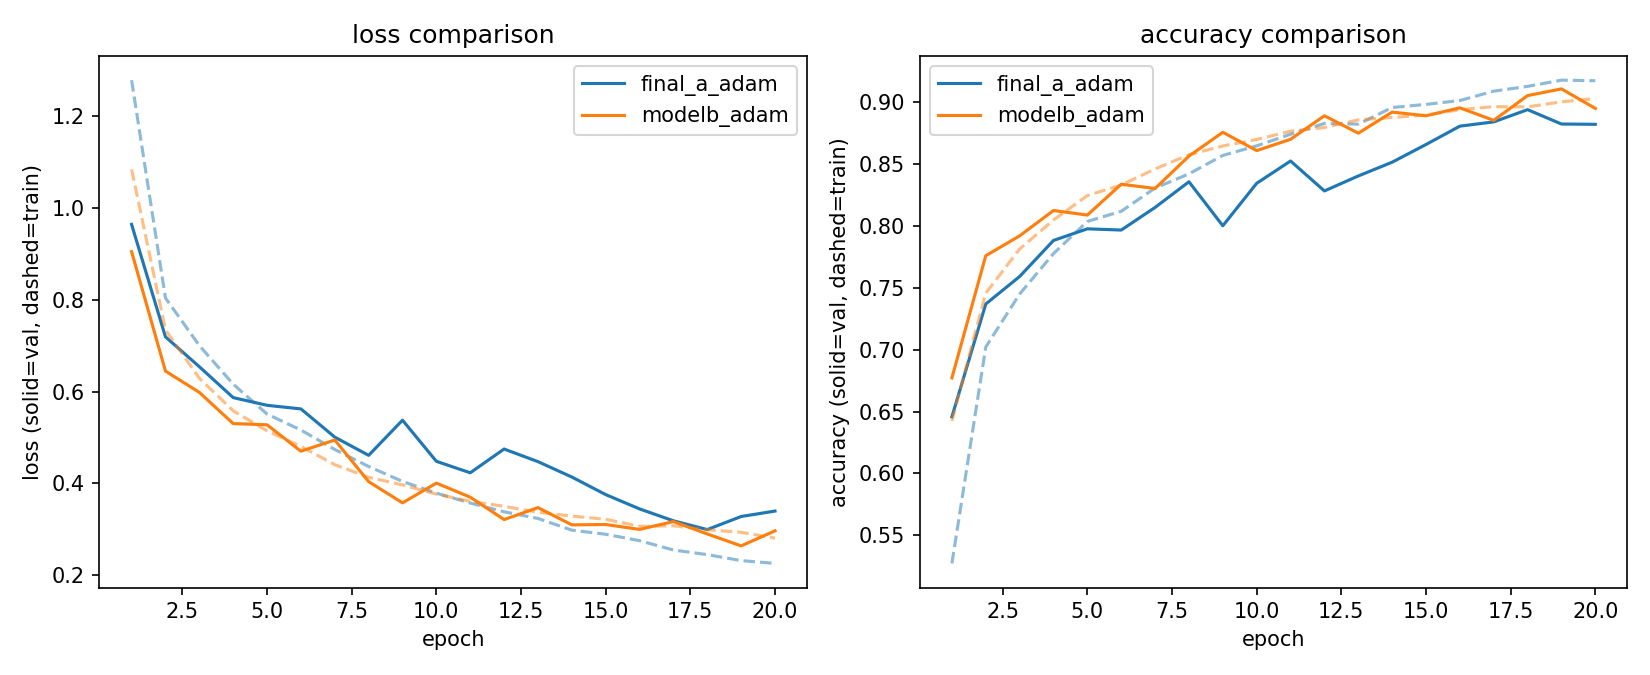

In [15]:
# Show all figures inline
for run in RUNS:
    display(Markdown(f"### {run}"))
    for f in ["loss_curve.png", "confusion_matrix.png"]:
        p = Path("outputs") / run / f
        if p.exists():
            display(Image(filename=str(p), width=520))
for f in ["modelb_optimizer_comparison.png", "modelA_vs_modelB_loss.png", "modela_optimizer_comparison.png"]:
    p = Path("outputs") / f
    if p.exists():
        display(Markdown(f"### {f}")); display(Image(filename=str(p), width=700))

In [16]:
# Extra measurements: 64x64 dataset audit, GPU/CPU benchmarks, and edge exports
!python tests/test_dataset_resolution.py --dataset-dir archive/EuroSAT > outputs/dataset_resolution_audit.txt
!cat outputs/dataset_resolution_audit.txt

!python -m src.benchmark --device cuda --runs 200 --out outputs/benchmark_gpu.csv
!python -m src.benchmark --device cpu  --runs 100 --out outputs/benchmark_cpu.csv

!pip install -q onnx onnxscript onnxruntime
!python -m src.export --model a --checkpoint outputs/final_a_adam/best_model.pt --out-dir outputs/edge_exports > outputs/edge_export_report.txt
!python -m src.export --model b --checkpoint outputs/modelb_adam/best_model.pt  --out-dir outputs/edge_exports >> outputs/edge_export_report.txt
!cat outputs/edge_export_report.txt

Dataset: archive/EuroSAT
Total image files: 27000
Resolution counts:
  64 x 64: 27000 images
Maximum resolution: 64 x 64
Unreadable files: 0
PASS: All images satisfy the maximum 64 x 64 requirement.

  EN3150 Hardware-Aware Edge Benchmark Profile
  Device: cuda | Batch Size: 1 | Iterations: 200

| Model                        | Input Shape   | Parameters   |   MACs (M) |   FLOPs (M) |   Latency (ms/img) |   Throughput (img/s) | Device   | Measurement                      |
|:-----------------------------|:--------------|:-------------|-----------:|------------:|-------------------:|---------------------:|:---------|:---------------------------------|
| Model A (Standard CNN)       | 3x64x64       | 549,290      |      11.73 |       23.46 |              0.411 |               2434.3 | CUDA     | synthetic input, untrained model |
| Model B (Depthwise-Sep. CNN) | 3x64x64       | 13,288       |       5.14 |       10.28 |              0.616 |               1624.2 | CUDA     | synthetic inpu

## Step 8: Save / download the results
- **Kaggle:** `results.zip` is written to `/kaggle/working` and appears in the notebook's **Output** tab after the committed run finishes.
- **Colab:** it's copied to `MyDrive/EN3150_A03_results.zip` and also offered as a browser download.

Unzip it into your local repo so that `outputs/` and the figures can be used in `report/main.tex`.

In [17]:
import shutil
zip_path = shutil.make_archive(str(WORK_DIR / "results"), "zip", root_dir=REPO_DIR, base_dir="outputs")
print("Created", zip_path)

if ON_COLAB:
    shutil.copy(zip_path, "/content/drive/MyDrive/EN3150_A03_results.zip")
    print("Copied to Google Drive: MyDrive/EN3150_A03_results.zip")
    from google.colab import files
    files.download(zip_path)

Created /kaggle/working/results.zip
